# Scary Stochastics, Week 5: Thompson Sampling
## Notebook 2 of 3 — Rival Vampires and the Hunter

Self-contained (the simulator block is repeated from Notebook 1). Five rivals hunt the same town as the Thompson Sampling vampire:

- **Random** — bites whoever.
- **Greedy** — always bites the class with the best average so far.
- **Epsilon-Greedy** — greedy, but 10% of nights bites at random.
- **UCB** — adds an optimism bonus to classes it knows little about.
- **Gaussian TS** — Thompson Sampling that wrongly assumes every class is Normal. This one separates *the algorithm* from *knowing the right model*.

Part 1 measures how much blood each strategy wastes. Part 2 adds the vampire hunter.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Vampire palette (extends the series palette with blood burgundy, midnight indigo and ivory)
PALETTE = {
    "burgundy": "#7A0C1E",  # blood burgundy - the Thompson Sampling vampire
    "indigo":   "#232A5C",  # midnight indigo
    "ivory":    "#FFFFF0",  # ivory - plot panels and light text
    "red":      "#C8102E",
    "orange":   "#E8741C",
    "rust":     "#B5451B",
    "purple":   "#3B2145",
    "mustard":  "#D9A404",
    "teal":     "#2A7F7F",
    "silver":   "#9AA5B4",
    "blue":     "#4682B4",
    "black":    "#1B1B1B",
    "cream":    "#FBF3E1",
}

plt.rcParams.update({
    "figure.facecolor": PALETTE["cream"],
    "axes.facecolor": PALETTE["ivory"],
    "axes.edgecolor": PALETTE["black"],
    "text.color": PALETTE["black"],
    "axes.labelcolor": PALETTE["black"],
    "xtick.color": PALETTE["black"],
    "ytick.color": PALETTE["black"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
})

In [2]:
# ---------------------------------------------------------------------------
# The town and its seven victim classes
# ---------------------------------------------------------------------------
CLASSES = ["Night Nurse", "Town Drunk", "Grandma", "Insomniac", "College Student", "Priest", "Sleepwalker"]
DISTS = ["Poisson(5)", "Normal(7, 2)", "Pareto(1.5)", "Gamma(2, 2)", "Poisson(10)", "Gamma(1, 1)", "Log-normal"]
CLASS_COLORS = [PALETTE["blue"], PALETTE["mustard"], PALETTE["rust"], PALETTE["purple"],
                PALETTE["orange"], PALETTE["silver"], PALETTE["teal"]]

K = 7                  # victim classes in town
N_NIGHTLY = 5          # classes on offer each night
TOWN_SIZE = 2500       # people in town: the hunter is 1 in 2,500 on a calm night
WARY_SCALE = 450.0     # every 450 pints drained adds +1 to the town's wariness
HAZARD_CAP = 0.05      # hunter chance per bite never exceeds 5%

PAR_ALPHA, PAR_XM = 1.5, 2.0      # Grandma: Pareto tail index and minimum yield
LN_MU, LN_SIGMA = 1.4, 0.7        # Sleepwalker: log-normal parameters
CAP = 40.0                        # cap on a sampled "expected yield" (Pareto can have a huge mean)

# Rates are "rate" (not "scale") for the Gamma classes, so Gamma(2, 2) averages 1 pint
TRUE_MEAN = np.array([5.0, 7.0, PAR_ALPHA * PAR_XM / (PAR_ALPHA - 1), 1.0, 10.0, 1.0,
                      np.exp(LN_MU + LN_SIGMA ** 2 / 2)])

def draw_yield(arm, rng):
    """Pints of blood from one bite on each vampire's chosen class (arm is an int array)."""
    y = np.empty(len(arm))
    for c in range(K):
        m = arm == c
        k = int(m.sum())
        if k == 0:
            continue
        if c == 0:   y[m] = rng.poisson(5.0, k)
        elif c == 1: y[m] = np.maximum(rng.normal(7.0, 2.0, k), 0)
        elif c == 2: y[m] = PAR_XM * (1 + rng.pareto(PAR_ALPHA, k))   # classic Pareto
        elif c == 3: y[m] = rng.gamma(2.0, 1 / 2.0, k)
        elif c == 4: y[m] = rng.poisson(10.0, k)
        elif c == 5: y[m] = rng.gamma(1.0, 1 / 1.0, k)
        else:        y[m] = rng.lognormal(LN_MU, LN_SIGMA, k)
    return y

# ---------------------------------------------------------------------------
# The vampire's beliefs: one conjugate posterior per class.
# n = bites so far, s = total pints, sl = total log-yield (Pareto: log(y / min yield))
# ---------------------------------------------------------------------------
def posterior_mean_draw(n, s, sl, rng):
    """One random draw of each class's EXPECTED yield from the vampire's current beliefs."""
    out = np.empty(n.shape)
    for c in (0, 4):   # Poisson classes: Gamma belief on the rate
        out[..., c] = rng.gamma(1.0 + s[..., c], 1.0 / (0.1 + n[..., c]))
    prec = 1 / 10.0 ** 2 + n[..., 1] / 2.0 ** 2    # Town Drunk: Normal belief on the mean (SD known)
    mean = (5.0 / 10.0 ** 2 + s[..., 1] / 2.0 ** 2) / prec
    out[..., 1] = rng.normal(mean, 1 / np.sqrt(prec))
    alpha = rng.gamma(1.0 + n[..., 2], 1.0 / (0.5 + sl[..., 2]))   # Grandma: Gamma belief on the tail index
    out[..., 2] = np.where(alpha > 1.05,
                           np.minimum(alpha * PAR_XM / np.maximum(alpha - 1, 1e-9), CAP), CAP)
    for c, shape in ((3, 2.0), (5, 1.0)):      # Gamma classes: Gamma belief on the rate (shape known)
        beta = rng.gamma(2.0 + shape * n[..., c], 1.0 / (1.0 + s[..., c]))
        out[..., c] = np.minimum(shape / beta, CAP)
    prec = 1 / 2.0 ** 2 + n[..., 6] / LN_SIGMA ** 2    # Sleepwalker: Normal belief on the log-scale mean
    mean = (1.0 / 2.0 ** 2 + sl[..., 6] / LN_SIGMA ** 2) / prec
    out[..., 6] = np.exp(rng.normal(mean, 1 / np.sqrt(prec)) + LN_SIGMA ** 2 / 2)
    return out

def pol_ts(n, s, sl, t, rng):
    """Thompson Sampling: score each class by one random draw from its posterior."""
    return posterior_mean_draw(n, s, sl, rng)

# ---------------------------------------------------------------------------
# The simulator: many vampires hunt in parallel (one row per vampire)
# ---------------------------------------------------------------------------
def simulate(policy, R, T, seed, hunter=False, snap=()):
    rng = np.random.default_rng(seed)
    n, s, sl = np.zeros((R, K)), np.zeros((R, K)), np.zeros((R, K))
    alive, drained, rows = np.ones(R, bool), np.zeros(R), np.arange(R)
    arm_log = np.full((R, T), -1, dtype=np.int8)
    y_log = np.zeros((R, T), dtype=np.float32)
    drained_log = np.zeros((R, T), dtype=np.float32)
    alive_log = np.zeros((R, T), dtype=bool)
    died_log = np.zeros((R, T), dtype=bool)
    regret = np.zeros((R, T))
    snaps = {}
    for t in range(T):
        if not alive.any():
            break
        # Five of the seven classes are on offer tonight (a fresh random five per vampire)
        cmask = np.zeros((R, K), bool)
        np.put_along_axis(cmask, np.argsort(rng.random((R, K)), axis=1)[:, :N_NIGHTLY], True, axis=1)
        arm = np.where(cmask, policy(n, s, sl, t, rng), -np.inf).argmax(axis=1)
        y = draw_yield(arm, rng)
        best = np.where(cmask, TRUE_MEAN, -np.inf).max(axis=1)
        # The hunter: 1 in TOWN_SIZE per bite, multiplied by the town's wariness
        wariness = 1 + drained / WARY_SCALE
        died = np.zeros(R, bool)
        if hunter:
            died = alive & (rng.random(R) < np.minimum(wariness / TOWN_SIZE, HAZARD_CAP))
        bite = alive & ~died
        idx, a, yy = rows[bite], arm[bite], y[bite]
        lg = np.log(np.maximum(yy, 1e-9))
        n[idx, a] += 1
        s[idx, a] += yy
        sl[idx, a] += np.where(a == 2, lg - np.log(PAR_XM), lg)
        arm_log[:, t] = np.where(alive, arm, -1)
        y_log[:, t] = np.where(bite, y, 0)
        drained_log[:, t] = drained
        alive_log[:, t] = alive
        died_log[:, t] = died
        regret[:, t] = np.where(alive, best - TRUE_MEAN[arm], 0)
        drained = drained + np.where(bite, y, 0)
        alive = bite
        if (t + 1) in snap:
            snaps[t + 1] = (n.copy(), s.copy(), sl.copy())
    return {"arm": arm_log, "y": y_log, "drained": drained_log, "alive": alive_log,
            "died": died_log, "regret": regret, "snaps": snaps}

In [3]:
# ---------------------------------------------------------------------------
# Rival vampires (each returns one score per class; the vampire bites the highest)
# ---------------------------------------------------------------------------
def pol_random(n, s, sl, t, rng):
    return rng.random(n.shape)

def pol_greedy(n, s, sl, t, rng):
    """Always bite the class with the best average so far (untried classes get tried first)."""
    avg = s / np.maximum(n, 1)
    return np.where(n > 0, avg, 1e6) + 1e-6 * rng.random(n.shape)

def pol_eps(n, s, sl, t, rng):
    """Greedy, but 10% of nights bite a random class."""
    explore = rng.random(n.shape[0]) < 0.10
    return np.where(explore[:, None], rng.random(n.shape), pol_greedy(n, s, sl, t, rng))

def pol_ucb(n, s, sl, t, rng):
    """Average plus an 'optimism bonus' that shrinks as a class gets bitten more."""
    avg = s / np.maximum(n, 1)
    bonus = 4.0 * np.sqrt(np.log(t + 2) / np.maximum(n, 1))
    return np.where(n > 0, avg + bonus, 1e6 + rng.random(n.shape))

def pol_gauss_ts(n, s, sl, t, rng):
    """Thompson Sampling that wrongly assumes every class is Normal with the same spread."""
    return rng.normal((6.0 + s) / (n + 1), 4.0 / np.sqrt(n + 1))

def pol_oracle(n, s, sl, t, rng):
    """Knows every class's true average from night one (the benchmark for regret)."""
    return np.tile(TRUE_MEAN, (n.shape[0], 1))

POLICIES = {"Random": pol_random, "Greedy": pol_greedy, "Epsilon-Greedy": pol_eps,
            "UCB": pol_ucb, "Gaussian TS": pol_gauss_ts, "Thompson Sampling": pol_ts}
POLICY_COLORS = {"Random": PALETTE["silver"], "Greedy": PALETTE["purple"],
                 "Epsilon-Greedy": PALETTE["orange"], "UCB": PALETTE["mustard"],
                 "Gaussian TS": PALETTE["teal"], "Thompson Sampling": PALETTE["burgundy"]}

### Part 1 — Wasted bites (regret)

Regret is the average yield of the best class on offer that night minus the average yield of the class actually bitten, summed over nights. We run 200 vampires per strategy for 600 nights each, with no hunter, so everyone gets a fair run.

In [4]:
R_REG, T_REG = 200, 600
reg = {name: simulate(pol, R_REG, T_REG, seed=100 + i) for i, (name, pol) in enumerate(POLICIES.items())}
oracle = simulate(pol_oracle, R_REG, T_REG, seed=99)

### Stress test — what if Grandma were the jackpot?

The heavy-tailed Grandma is this town's trap: her yields are usually modest but occasionally enormous, so her *sample* average usually undershoots her true average. To see what that does, we re-run all six strategies in a second town where Grandma's tail is heavier (Pareto 1.2), making her the richest victim at 12 pints on average. The vampires aren't told about the change.

In [5]:
# Make Grandma's tail heavier (true average 12 pints), run everyone, then restore the town
PAR_ALPHA_DESIGNED = PAR_ALPHA
PAR_ALPHA = 1.2
TRUE_MEAN[2] = PAR_ALPHA * PAR_XM / (PAR_ALPHA - 1)
stress = {name: simulate(pol, R_REG, T_REG, seed=100 + i) for i, (name, pol) in enumerate(POLICIES.items())}
PAR_ALPHA = PAR_ALPHA_DESIGNED
TRUE_MEAN[2] = PAR_ALPHA * PAR_XM / (PAR_ALPHA - 1)

### Visual 4 — Cumulative regret

Lines are averages over 200 vampires; bands cover the middle 80%. Lower is better.

**Left, the town as designed (Grandma averages 6 pints):** Random and Epsilon-Greedy keep wasting bites on exploration that never stops, as expected. But Thompson Sampling also finishes behind Greedy, UCB and Gaussian TS over these 600 nights. The reason is Grandma: a correct Pareto belief about her average stays wide and lopsided, so the vampire keeps checking whether she's a jackpot (she gets a visibly bigger share of its bites in Visual 5). That's an insurance premium, and in this town the insurance doesn't pay out. Try `T_REG = 2000` to watch its curve flatten while Epsilon-Greedy's keeps climbing.

**Right, the stress test (Grandma averages 12 pints):** now the premium pays. Thompson Sampling's regret is about half the others' or less, because it learns her heavy tail from the *logarithm* of each yield instead of the raw average, so it finds her. The rivals' averages mislead them. The lesson isn't that Thompson Sampling always wins; it's that its beliefs stay honest about what it doesn't know.

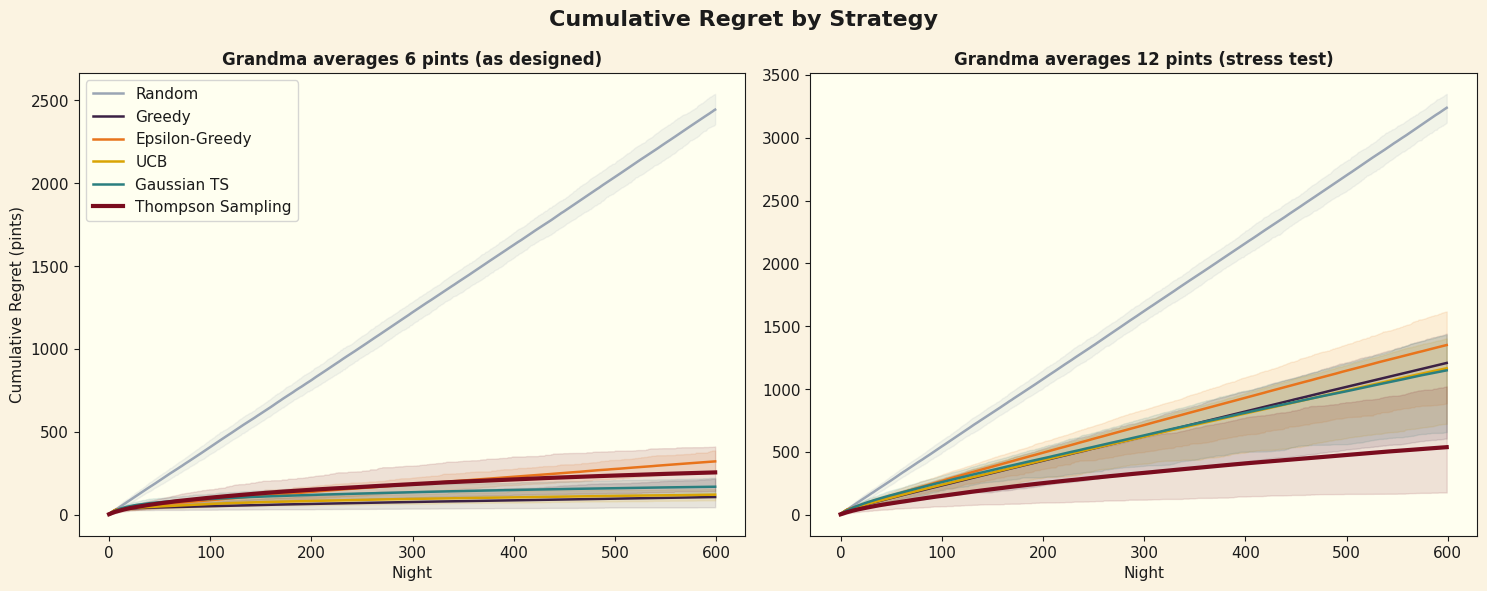

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, results, title in zip(axes, [reg, stress],
                              ["Grandma averages 6 pints (as designed)", "Grandma averages 12 pints (stress test)"]):
    for name, res in results.items():
        cum = np.cumsum(res["regret"], axis=1)
        lo, hi = np.percentile(cum, [10, 90], axis=0)
        ax.plot(cum.mean(axis=0), color=POLICY_COLORS[name],
                linewidth=3 if name == "Thompson Sampling" else 1.8, label=name)
        ax.fill_between(np.arange(T_REG), lo, hi, color=POLICY_COLORS[name], alpha=0.12)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Night")
axes[0].set_ylabel("Cumulative Regret (pints)")
axes[0].legend(loc="upper left")
fig.suptitle("Cumulative Regret by Strategy", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("04_cumulative_regret.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Visual 5 — Who each vampire feeds on

Share of bites by victim class. The top bar is the Oracle, who knows every average from night one. The closer a strategy's bar is to the Oracle's, the better it has learned who is worth biting. (Each class is only on offer 5 nights in 7, which is why even the Oracle bites a mix.) Thompson Sampling's larger Grandma slice is the insurance premium from Visual 4.

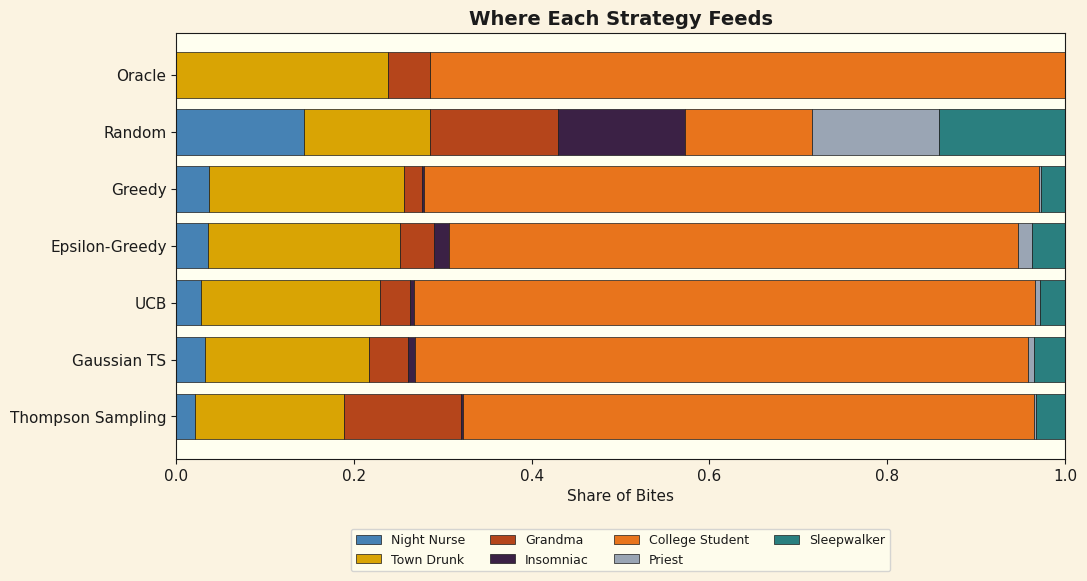

In [7]:
shares = {}
for name, res in {"Oracle": oracle, **reg}.items():
    a = res["arm"][res["arm"] >= 0]
    shares[name] = np.bincount(a, minlength=K) / len(a)

fig, ax = plt.subplots(figsize=(11, 6))
names = list(shares)[::-1]
left = np.zeros(len(names))
for c in range(K):
    vals = np.array([shares[nm][c] for nm in names])
    ax.barh(names, vals, left=left, color=CLASS_COLORS[c], edgecolor=PALETTE["black"],
            linewidth=0.5, label=CLASSES[c])
    left += vals
ax.set_xlabel("Share of Bites")
ax.set_title("Where Each Strategy Feeds")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=9)
plt.tight_layout()
plt.savefig("05_strategy_feeding.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Part 2 — Enter the vampire hunter

The town has 2,500 people, and one of them is a vampire hunter. On a calm night, each bite has a **1-in-2,500 chance** of landing on the hunter, which ends the run. But the town gets wary: every 450 pints drained adds +1 to a **wariness multiplier** that scales that chance (capped at 5% per bite). A vampire that feeds efficiently is also the one the town notices.

Because one unlucky night can end any single run, we simulate 1,000 vampires per strategy and look at distributions, not stories.

In [8]:
R_GAME, T_GAME = 1000, 2500
game = {name: simulate(pol, R_GAME, T_GAME, seed=200 + i, hunter=True)
        for i, (name, pol) in enumerate(POLICIES.items())}
lifespan = {name: g["alive"].sum(axis=1) for name, g in game.items()}
blood = {name: g["y"].sum(axis=1) for name, g in game.items()}

pd.DataFrame({
    "Mean nights alive": {k: v.mean() for k, v in lifespan.items()},
    "Median nights alive": {k: np.median(v) for k, v in lifespan.items()},
    "Mean pints drained": {k: v.mean() for k, v in blood.items()},
    "Survive 500 nights": {k: (v > 500).mean() for k, v in lifespan.items()},
}).round(2)

,Mean nights alive,Median nights alive,Mean pints drained,Survive 500 nights
Random,505.28,482.0,2530.750000,0.47
Greedy,401.24,377.0,3552.840088,0.28
Epsilon-Greedy,409.51,391.5,3483.860107,0.31
UCB,398.12,365.5,3515.530029,0.30
Gaussian TS,395.43,361.0,3439.110107,0.31
Thompson Sampling,410.56,379.5,3527.419922,0.33


### Visual 6 — Survival curves

The share of vampires still alive after each night. Everyone who learns drains richer blood, so the town grows wary sooner and their curves fall faster than Random's. The learners cluster tightly together.

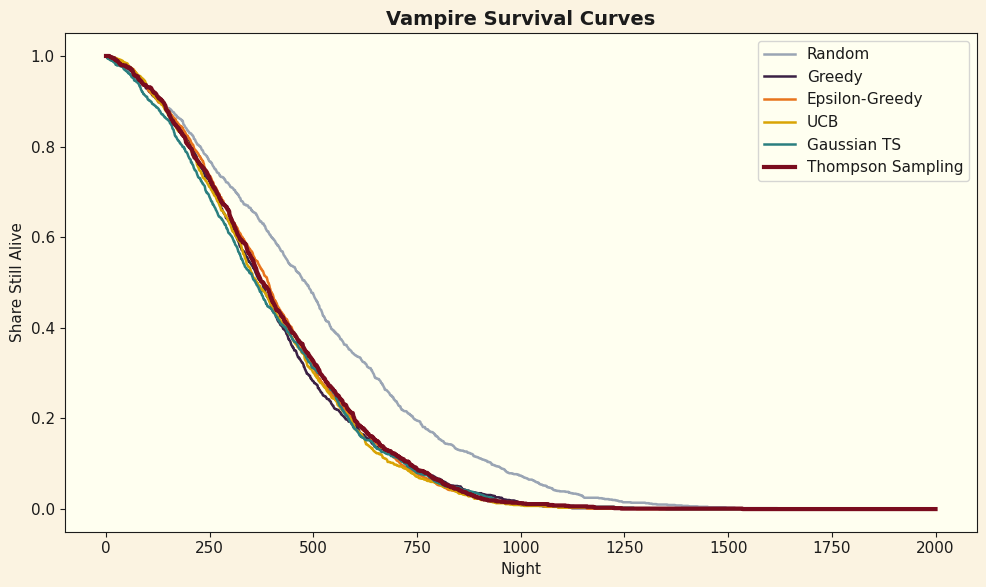

In [9]:
ts = np.arange(0, 2001)
fig, ax = plt.subplots(figsize=(10, 6))
for name in POLICIES:
    surv = np.mean(lifespan[name][:, None] > ts[None, :], axis=0)
    ax.plot(ts, surv, color=POLICY_COLORS[name], linewidth=3 if name == "Thompson Sampling" else 1.8,
            label=name)
ax.set_xlabel("Night")
ax.set_ylabel("Share Still Alive")
ax.set_title("Vampire Survival Curves")
ax.legend()
plt.tight_layout()
plt.savefig("06_survival_curves.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Visual 7 — The town gets wary

Median wariness multiplier among vampires still alive on each night (left axis), and the matching hunter chance per bite (right axis). The learners climb together and faster than Random, because they drain more blood per night. Late in each line the curve reflects only the few survivors, so it gets noisier.

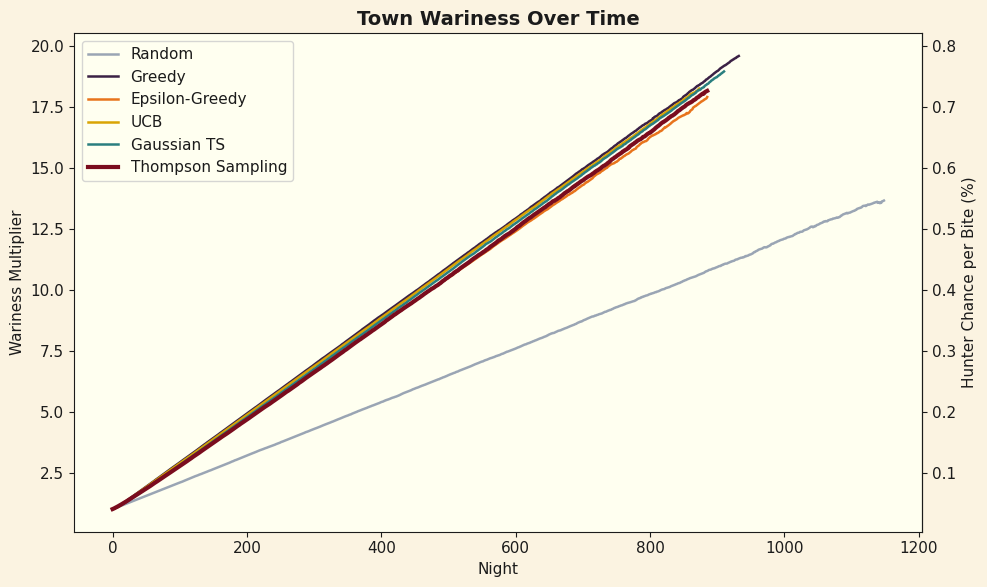

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
for name, g in game.items():
    W = 1 + g["drained"] / WARY_SCALE
    med = np.array([np.median(W[g["alive"][:, t], t]) if g["alive"][:, t].sum() >= 30 else np.nan
                    for t in range(T_GAME)])
    ax.plot(med, color=POLICY_COLORS[name], linewidth=3 if name == "Thompson Sampling" else 1.8, label=name)
ax.set_xlabel("Night")
ax.set_ylabel("Wariness Multiplier")
ax.set_title("Town Wariness Over Time")
sec = ax.secondary_yaxis("right", functions=(lambda w: 100 * w / TOWN_SIZE, lambda p: p * TOWN_SIZE / 100))
sec.set_ylabel("Hunter Chance per Bite (%)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("07_town_wariness.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Visual 8 — Shorter lives, more blood

Mean lifespan and mean total blood per strategy, with 95% confidence intervals. The clear split is between Random and everyone who learns: learners live about 20% fewer nights (their bites are richer, so the town grows wary sooner) but drain about 40% more blood. Among the learners the differences are small and the intervals overlap, so don't read a winner into the bar heights — in this town, learning at all is worth far more than which learning rule you use.

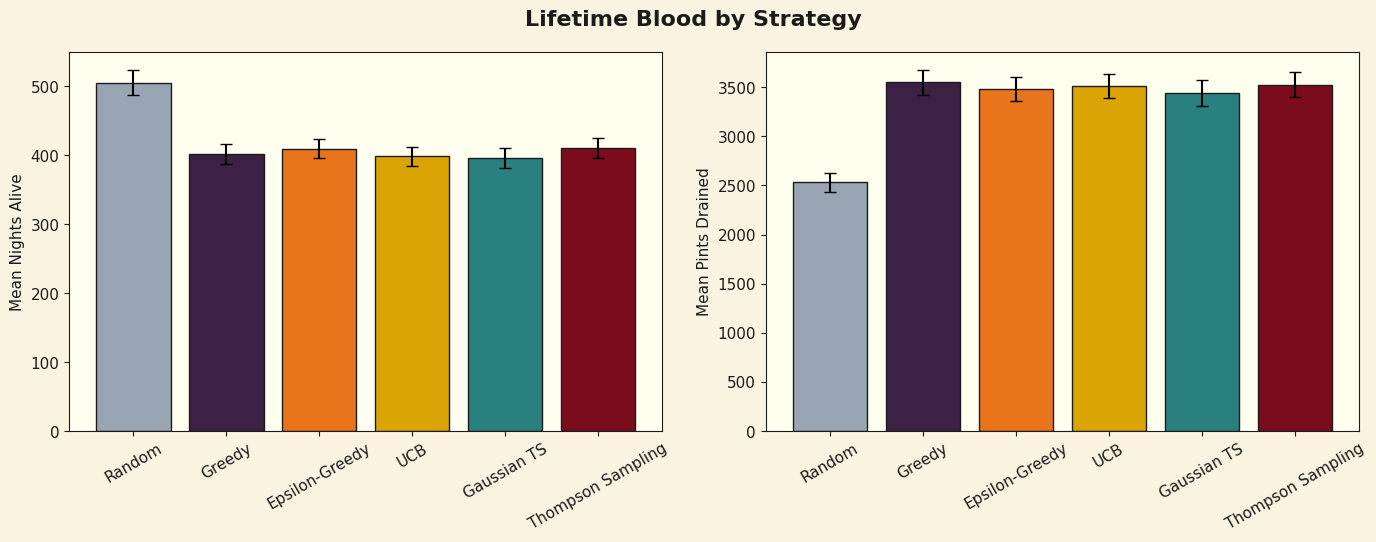

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, data, label in zip(axes, [lifespan, blood], ["Mean Nights Alive", "Mean Pints Drained"]):
    means = np.array([data[nm].mean() for nm in POLICIES])
    cis = np.array([1.96 * data[nm].std(ddof=1) / np.sqrt(len(data[nm])) for nm in POLICIES])
    ax.bar(list(POLICIES), means, yerr=cis, color=[POLICY_COLORS[nm] for nm in POLICIES],
           edgecolor=PALETTE["black"], capsize=4)
    ax.set_ylabel(label)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Lifetime Blood by Strategy", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("08_lifetime_blood.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Up next

Notebook 3 shows how the whole system fits together, benchmarks how the town is stored in memory, and trains two classifiers on the bite logs.